# BARC Corn Grain and Silage Fields, 2021-2023

`BARC_Corn.2021-2023.gpkg` contains 83 BARC field multipolygons in NAD83 / Maryland (US survey feet). The yearly columns `Corn_2021`, `Corn_2022`, and `Corn_2023` hold the reference labels `Silage` or `Grain`: silage or grain corn that was planted and harvested in that year. Blank values are not labeled examples.

Across the three years there are 44 labeled field-years (32 Grain, 12 Silage) on 34 unique polygons. Some fields are labeled in more than one year.

This data was prepared by the Beltsville Agricultural Research Center (BARC). You can learn more about the data [here](https://www.ars.usda.gov/research/publications/publication/?seqNo115=404951) and the NAD83 mapping reference system [here](https://www.ngs.noaa.gov/datums/horizontal/north-american-datum-1983.shtml).

This notebook loads the data, reshapes the labels into a field-year evaluation table, and creates simple map and class-summary views.

If you use or redistribute these data, please cite the original publications and datasets listed in the **References** section at the end of this notebook.

# BARC Corn Grain and Silage Fields, 2021-2023

`BARC_Corn.2021-2023.gpkg` contains 83 BARC field multipolygons in NAD83 / Maryland (US survey feet). The yearly columns `Corn_2021`, `Corn_2022`, and `Corn_2023` hold the reference labels `Silage` or `Grain`: silage or grain corn that was planted and harvested in that year. Blank values are not labeled examples.

Across the three years there are 44 labeled field-years (32 Grain, 12 Silage) on 34 unique polygons. Some fields are labeled in more than one year.

This data was prepared by the Beltsville Agricultural Research Center (BARC). You can learn more about the data [here](https://www.ars.usda.gov/research/publications/publication/?seqNo115=404951) and the NAD83 mapping reference system [here](https://www.ngs.noaa.gov/datums/horizontal/north-american-datum-1983.shtml).

This notebook loads the data, reshapes the labels into a field-year evaluation table, and creates simple map and class-summary views.

If you use or redistribute these data, please cite the original publications and datasets listed in the **References** section at the end of this notebook.

## 1. Install packages

Run once in a new environment.

In [3]:
%pip install geopandas matplotlib pandas pyogrio

Defaulting to user installation because normal site-packages is not writeable
DEPRECATION: Loading egg at /Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/seaborn-0.11.2-py3.11.egg is deprecated. pip 25.1 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330

[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Load the GeoPackage

The source layer is `barc_silage_grain_corn20212023`.

In [4]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt

DATA_PATH = Path("BARC_Corn.2021-2023.gpkg")
LAYER = "barc_silage_grain_corn20212023"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected {DATA_PATH.resolve()}")

fields = gpd.read_file(DATA_PATH, layer=LAYER)
print(f"Fields: {len(fields)}")
print(f"CRS: {fields.crs}")
fields[
    [
        "OBJECTID",
        "GROWER",
        "FARM",
        "FIELD",
        "ACRES",
        "Corn_2021",
        "Corn_2022",
        "Corn_2023",
    ]
].head()

Fields: 83
CRS: PROJCS["NAD83 / Maryland (ftUS)",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",37.6666666666667],PARAMETER["central_meridian",-77],PARAMETER["standard_parallel_1",38.3],PARAMETER["standard_parallel_2",39.45],PARAMETER["false_easting",1312333.33333333],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]


,OBJECTID,GROWER,FARM,FIELD,ACRES,Corn_2021,Corn_2022,Corn_2023
0,1,B.A.R.C.,APU,1,16.402068,Grain,None,Grain
1,4,B.A.R.C.,APU,1-97,10.401865,None,None,None
2,5,B.A.R.C.,APU,1-98,8.512575,None,None,None
3,14,B.A.R.C.,APU,18,6.313873,None,None,None
4,22,B.A.R.C.,APU,28,14.846976,None,None,None


## 3. Create one labeled row per field-year

`labeled_fields` keeps only the reference-labeled field-years. Use `OBJECTID` and `year` to join a model's predictions; do not score blank source labels.

In [5]:
LABEL_COLUMNS = {"Corn_2021": 2021, "Corn_2022": 2022, "Corn_2023": 2023}

labeled_fields = (
    fields.melt(
        id_vars=["OBJECTID", "GROWER", "FARM", "FIELD", "ACRES", "geometry"],
        value_vars=LABEL_COLUMNS,
        var_name="label_column",
        value_name="harvest_type",
    )
    .assign(year=lambda frame: frame["label_column"].map(LABEL_COLUMNS))
    .dropna(subset=["harvest_type"])
    .query("harvest_type in ['Grain', 'Silage']")
    .drop(columns="label_column")
    .sort_values(["year", "harvest_type", "OBJECTID"])
)

print(f"Labeled field-years: {len(labeled_fields)}")
print(f'Unique labeled polygons: {labeled_fields["OBJECTID"].nunique()}')
print(labeled_fields["harvest_type"].value_counts().to_string())

unexpected = (
    fields[list(LABEL_COLUMNS)].stack().loc[lambda s: ~s.isin(["Grain", "Silage"])]
)
if not unexpected.empty:
    print(f"Warning: ignored unexpected label values: {sorted(unexpected.unique())}")

labeled_fields[["OBJECTID", "year", "harvest_type", "ACRES"]].head()

Labeled field-years: 44
Unique labeled polygons: 34
harvest_type
Grain     32
Silage    12


,OBJECTID,year,harvest_type,ACRES
0,1,2021,Grain,16.402068
6,24,2021,Grain,14.212752
18,238,2021,Grain,17.380502
79,263,2021,Grain,32.614318
31,286,2021,Grain,6.502192


## 4. Review label coverage

Check class balance before designing validation splits.

In [6]:
field_counts = (
    labeled_fields.groupby(["year", "harvest_type"]).size().unstack(fill_value=0)
)
acreage = (
    labeled_fields.groupby(["year", "harvest_type"])["ACRES"]
    .sum()
    .unstack(fill_value=0)
)

display(field_counts)
display(acreage.round(1))

harvest_type,Grain,Silage
year,,
2021,14,4
2022,3,4
2023,15,4


harvest_type,Grain,Silage
year,,
2021,245.1,76.5
2022,35.9,74.4
2023,196.2,108.0


## 5. Map labeled fields

Choose a year. Gold polygons are Grain and green polygons are Silage; gray outlines show all BARC fields.

/var/folders/zr/2wb4s69j7kl53vcr3tq54zpw0000gn/T/ipykernel_16954/1513683362.py:27: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc="upper right")


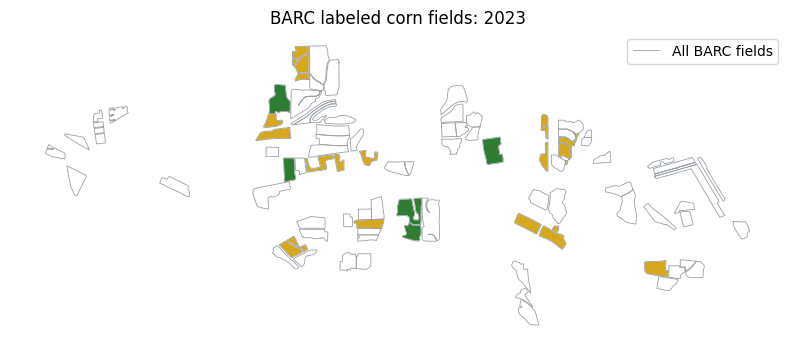

In [7]:
YEAR_TO_MAP = 2023
COLORS = {"Grain": "#d6a81d", "Silage": "#2f7d32"}
year_labels = gpd.GeoDataFrame(
    labeled_fields[labeled_fields["year"] == YEAR_TO_MAP],
    geometry="geometry",
    crs=fields.crs,
)

if year_labels.empty:
    raise ValueError(f"No Grain or Silage labels found for {YEAR_TO_MAP}.")

fig, ax = plt.subplots(figsize=(10, 8))
fields.boundary.plot(ax=ax, color="#9aa0a6", linewidth=0.6, label="All BARC fields")
for harvest_type, color in COLORS.items():
    subset = year_labels[year_labels["harvest_type"] == harvest_type]
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=color,
            edgecolor="white",
            linewidth=0.5,
            label=f"{harvest_type} ({len(subset)} fields)",
        )

ax.set_title(f"BARC labeled corn fields: {YEAR_TO_MAP}")
ax.set_axis_off()
ax.legend(loc="upper right")
plt.show()

## 6. Plot reference-label counts

This shows labeled field counts, not acreage.

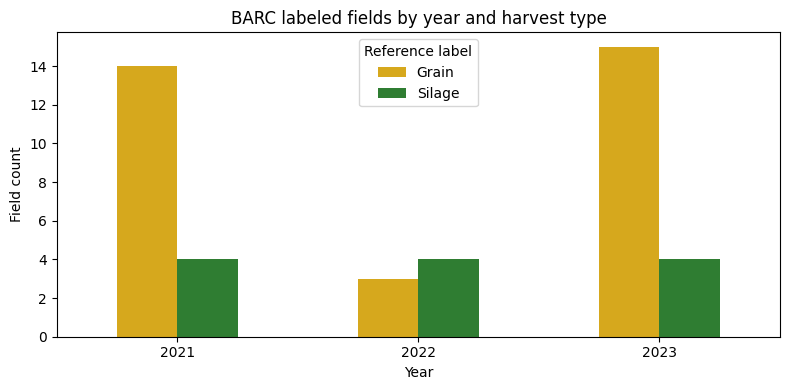

In [8]:
plot_counts = field_counts.reindex(columns=["Grain", "Silage"], fill_value=0)
ax = plot_counts.plot(
    kind="bar", color=[COLORS["Grain"], COLORS["Silage"]], figsize=(8, 4), rot=0
)
ax.set(
    title="BARC labeled fields by year and harvest type",
    xlabel="Year",
    ylabel="Field count",
)
ax.legend(title="Reference label")
plt.tight_layout()
plt.show()

## Evaluation Notes

Keep source labels unchanged and store model predictions separately. At minimum, report a confusion matrix plus class-specific precision and recall. Because the labeled data are small and nearby fields can share management or imagery conditions, prefer holding out a year or spatially separated fields over a purely random split.

## References

The BARC field polygons were originally developed and published in the studies below. Please cite the relevant publications and datasets when using or redistributing these data.

**Publications**

* Dulaney, W., Anderson, M., Gao, F., Stern, A., Moglen, G., Meyers, G., Daughtry, C., White, W., Akumaga, U., & Showalter, J. (2024). Development of a gridded yield data archive for farm management and research at the USDA Beltsville Agricultural Research Center. *Agrosystems, Geosciences & Environment*, 7(1), e20474. https://doi.org/10.1002/agg2.20474
* Kraatz, S., Lamb, B., Hively, W., Jennewein, J., Gao, F., Cosh, M., & Siqueira, P. (2023). Comparing NISAR (Using Sentinel-1), USDA/NASS CDL, and Ground Truth Crop/Non-Crop Areas in an Urban Agricultural Region. *Sensors*, 23(20), 8595. https://doi.org/10.3390/s23208595

**Datasets**

* USDA Beltsville Agricultural Research Center (BARC) Gridded Yield Data Archive, version 1. USDA National Agricultural Library, Ag Data Commons. https://agdatacommons.nal.usda.gov/articles/dataset/USDA_Beltsville_Agricultural_Research_Center_BARC_Gridded_Yield_Data_Archive_version_1/28950746
* Kraatz, S. (2023). Validating NISAR's cropland mapping approach and the USDA/NASS Cropland Data Layer against ground truth data in a fragmented urban agricultural region (Version 1.0.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.8087301